In [ ]:
!pip -q install modern_robotics

import modern_robotics as mr

In [ ]:
import numpy as np

In [ ]:
print(mr.__name__)

modern_robotics


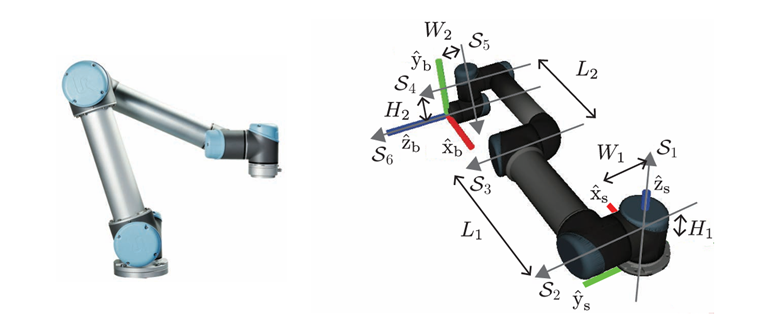

### ***UR5 robot of Example 4.5 of Chapter 4.1.2 (Figure 4.6)***

In [ ]:
W1 = 109.0/1000
W2 = 82.0/1000
L1 = 425.0/1000
L2 = 392.0/1000
H1 = 89.0/1000
H2 = 95.0/1000

theta=np.array([0,-np.pi/2,0,0,np.pi/2,0])

M_UR5 = np.array([
    [-1, 0, 0, L1 + L2],
    [ 0, 0, 1, W1 + W2],
    [ 0, 1, 0, H1 - H2],
    [ 0, 0, 0,       1]
])

S1=np.array([[0,0,1,0,0,0]])
S2=np.array([[0,1,0,-H1,0,0]])

#Remember to multiply -q
w3=np.array([[0,1,0]])
q3=np.array([[L1,W1,H1]])
v3=np.cross(w3,-q3)
S3=np.hstack((w3,v3))

w4=np.array([[0,1,0]])
q4=np.array([[L1+L2,0,H1]])
v4 = np.cross(w4, -q4)
S4 = np.hstack((w4, v4))

w5=np.array([[0,0,-1]])
q5=np.array([[L1+L2,W1,H1]])
v5 = np.cross(w5, -q5)
S5 = np.hstack((w5, v5))

w6=np.array([[0,1,0]])
q6=np.array([[L1+L2,W1,H2-H1]])
v6 = np.cross(w6, -q6)
S6 = np.hstack((w6, v6))

S_UR5=np.vstack((S1,S2,S3,S4,S5,S6))

T_bs=mr.TransInv(M_UR5)
Ad_Tbs=mr.Adjoint(T_bs)
B_UR5=Ad_Tbs@S_UR5.T

print(B_UR5)


[[ 0.     0.     0.     0.     0.     0.   ]
 [ 1.     0.     0.     0.    -1.     0.   ]
 [ 0.     1.     1.     1.     0.     1.   ]
 [ 0.191  0.095  0.095  0.095 -0.082  0.012]
 [ 0.    -0.817 -0.392  0.     0.     0.   ]
 [ 0.817  0.     0.     0.     0.     0.   ]]


In [ ]:
theta_guest=np.array([np.pi,-np.pi/2,0,0,np.pi/2,0])

In [ ]:
T_goal = np.array([
    [ 0,  1,  0, -0.5],
    [ 0,  0, -1,  0.1],
    [-1,  0,  0,  0.1],
    [ 0,  0,  0,  1.0]
])

In [ ]:
def IKinBodyIterates(Blist=B_UR5 ,M=M_UR5,T=T_goal,thetalist0=theta_guest,eomg=0.001,ev=0.0001,max_iteration=25):
  #Blist: The joint screw axes in the end-effector frame when the manipulator is at the home position.
  #M: The home configuration of the end-effector.
  #T: The desired end-effector configuration Tsd.
  #thetalist0: An initial guess θ0 ∈ Rn that is “close” to satisfying T(θ0) = Tsd.
  #eomg: A small positive tolerance on the end-effector orientation error. The returned joint variables must give an end-effector orientation error less than ω.
  #ev: A small positive tolerance on the end-effector linear position error. The returned joint
  #variables must give an end-effector position error less than ν.
  iteration=0
  error_twist=[]
  joint_theta = thetalist0.reshape(1,-1)
  total_wb=[]
  total_vb=[]
  while True:
    T_sb = mr.FKinBody(M,Blist,thetalist0)
    T_err = mr.TransInv(T_sb) @ T
    skew_matrix_Vb= se3mat = mr.MatrixLog6(T_err)
    Vb=mr.se3ToVec(skew_matrix_Vb)
    error_twist.append(Vb)
    wb=Vb[0:3]
    vb=Vb[3:6]
    total_wb.append(np.linalg.norm(wb))
    total_vb.append(np.linalg.norm(vb))
    if (np.linalg.norm(wb) < eomg and np.linalg.norm(vb) < ev) or iteration >= max_iteration:
            break
    Jb = mr.JacobianBody(Blist, thetalist0)
    d_theta = (np.linalg.pinv(Jb) @ Vb).flatten()
    thetalist0 = thetalist0 + d_theta
    joint_theta=np.vstack((joint_theta,thetalist0.reshape(1,-1)))
    iteration += 1
  return iteration,error_twist,wb,vb,joint_theta,total_wb,total_vb

In [ ]:
iteration,error_twist,wb,vb, joint_theta,total_wb,total_vb =IKinBodyIterates(Blist=B_UR5 ,M=M_UR5,T=T_goal,thetalist0=theta_guest,eomg=0.001,ev=0.0001)


In [ ]:
for i in range(25):
  random_theta_guest=np.random.uniform(-np.pi,np.pi,6)
  iteration,error_twist,wb,vb, joint_theta,total_wb,total_vb =IKinBodyIterates(Blist=B_UR5 ,M=M_UR5,T=T_goal,thetalist0=random_theta_guest,eomg=0.001,ev=0.0001)
  if iteration < 25:
    print(iteration)
    print(random_theta_guest)
    print(wb)
    print(vb)
    np.savetxt("iterates.csv", joint_theta, delimiter=",")
    break
  else:
    print("try_again")

14
[-1.1854605   0.62394671  0.55562283  1.57772557 -1.40609241 -2.35283305]
[-3.46507851e-08 -1.10191381e-07 -5.93545644e-08]
[-3.63898496e-07 -2.94120363e-07 -5.73435422e-08]


In [ ]:
print(total_wb)

[np.float64(1.5707963267948966), np.float64(1.9537947198636627), np.float64(0.6454772310854723), np.float64(0.6711354550689317), np.float64(1.5353438374123918), np.float64(1.834959853047355), np.float64(0.037820908034689245), np.float64(0.010146374742977297), np.float64(0.08278681417883552), np.float64(0.4219342879881352), np.float64(0.9614573461878538), np.float64(0.9979285313167223), np.float64(1.7108293830436252), np.float64(0.7235799467356123), np.float64(0.6446469463643311), np.float64(0.909005064090538), np.float64(1.5001270483626017), np.float64(0.8451901700136323), np.float64(0.5999199451053117), np.float64(0.6162457040923393), np.float64(0.4056586458867895), np.float64(0.011301991895362693), np.float64(0.01555146546238735), np.float64(0.024099889575901864), np.float64(0.006404026331482923), np.float64(0.0002294891165688586)]


In [ ]:
np.savetxt("iterates.csv", joint_theta, delimiter=",")